# Ford Car Price Prediction — Improved Workflow

This improved notebook retains the original EDA, Linear Regression baseline, cross-validation model comparison, error inspection, and evaluation workflow. It improves input-data validation, consistent categorical normalization, model-selection-driven tuning, prediction helper consistency, metric reporting, and model artifact export.

## Original-run metrics (historical reference)
These values were provided from the original notebook run. They are reference values, not results from executing this improved notebook. The improved workflow should be run again to calculate its own scores.

| Model / split | RMSE | MAE | R² |
|---|---:|---:|---:|
| Linear Regression — train | 1,848.503 | 1,361.339 | 0.847 |
| Linear Regression — test | 1,808.697 | 1,351.265 | 0.858 |
| Tuned HistGradientBoosting — train | 1,019.944 | 720.680 | 0.953329 |
| Tuned HistGradientBoosting — test | 1,133.002 | 809.979 | 0.944158 |

Original test MAPE: **6.95%**. Original cross-validation comparison ranked HistGradientBoostingRegressor first (RMSE 1,219.192), followed by RandomForestRegressor (RMSE 1,289.784). The original tuned HGB parameters were `learning_rate=0.1`, `max_depth=None`, `max_leaf_nodes=63`, `min_samples_leaf=20`, and `l2_regularization=0.1`.

## Path and artifact note
Set `FORD_CSV_PATH` to the dataset file and `FORD_MODEL_PATH` to an absolute model artifact path. Use the **same absolute `FORD_MODEL_PATH`** when running this notebook and the API. The API loads the serialized full preprocessing-and-regression pipeline, not only the estimator. Train and serve with compatible versions of scikit-learn.


In [1]:
import os
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import (
    train_test_split,
    KFold,
    RandomizedSearchCV,
    cross_validate,
    ParameterGrid,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
)


In [2]:
# Configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")
sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

RANDOM_STATE = 42
TARGET_COL = "price"

# Prefer an explicit environment path; otherwise try common project layouts.
if os.getenv("FORD_CSV_PATH"):
    CSV_PATH = Path(os.environ["FORD_CSV_PATH"]).expanduser().resolve()
    if not CSV_PATH.is_file():
        raise FileNotFoundError(f"FORD_CSV_PATH does not exist: {CSV_PATH}")
else:
    csv_candidates = [
        Path("../data/ford.csv"),
        Path("ford.csv"),
        Path("data/ford.csv"),
        Path("../ford.csv"),
    ]
    CSV_PATH = next(
        (candidate.resolve() for candidate in csv_candidates if candidate.is_file()),
        None,
    )
    if CSV_PATH is None:
        raise FileNotFoundError(
            "Could not locate ford.csv. Set FORD_CSV_PATH to its absolute path."
        )

DEFAULT_MODEL_PATH = Path("../models/ford_price_model.pkl").resolve()
MODEL_PATH = Path(
    os.getenv("FORD_MODEL_PATH", str(DEFAULT_MODEL_PATH))
).expanduser().resolve()

print("Dataset:", CSV_PATH)
print("Model output:", MODEL_PATH)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)


Dataset: E:\AI\Projects\Project02_FordCardPricePrediction\data\ford.csv
Model output: E:\AI\Projects\Project02_FordCardPricePrediction\models\ford_price_model.pkl
Python: 3.11.14
pandas: 3.0.5
NumPy: 2.4.6
scikit-learn: 1.9.1
joblib: 1.6.0


Load Data

In [3]:
df = pd.read_csv(CSV_PATH)
print("Raw dataset shape:", df.shape)
display(df.head())


Raw dataset shape: (17966, 9)


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.700,1.000
1,Focus,2018,14000,Manual,9083,Petrol,150,57.700,1.000
2,Focus,2017,13000,Manual,12456,Petrol,150,57.700,1.000
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.300,1.500
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.700,1.000


In [4]:
df.shape

(17966, 9)

In [5]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.700,1.000
1,Focus,2018,14000,Manual,9083,Petrol,150,57.700,1.000
2,Focus,2017,13000,Manual,12456,Petrol,150,57.700,1.000
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.300,1.500
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.700,1.000


In [6]:
# Normalize category values exactly as the inference service does.
categorical_cols = ["model", "transmission", "fuelType"]
required_columns = [
    "model", "year", "price", "transmission", "mileage",
    "fuelType", "tax", "mpg", "engineSize",
]

missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {sorted(missing_columns)}"
    )

df = df[required_columns].copy()

for col in categorical_cols:
    values = df[col].astype("string").str.strip().str.casefold()
    df[col] = values.mask(values.eq(""), np.nan).astype(object)

for col in ["year", "price", "mileage", "tax", "mpg", "engineSize"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


In [7]:
# Dataset inspection found one record with year=2060, outside the source's
# otherwise observed 1996-2020 range. Keep only the validated training range.
rows_before_cleaning = len(df)
df = df.loc[df["year"].between(1996, 2020)].copy()
df = df.loc[df["price"].gt(0)].copy()
df = df.loc[
    df["mileage"].ge(0)
    & df["tax"].ge(0)
    & df["mpg"].gt(0)
    & df["engineSize"].ge(0)
].copy()

# A zero engine displacement is not plausible for the listed conventional cars
# in this source, so treat it as missing and let the training-only imputer fill it.
zero_engine_size_count = int(df["engineSize"].eq(0).sum())
df.loc[df["engineSize"].eq(0), "engineSize"] = np.nan

# Rows with invalid target or year cannot be imputed for supervised learning.
df = df.dropna(subset=["year", TARGET_COL]).copy()
df["year"] = df["year"].astype(int)

print("Rows excluded by validation:", rows_before_cleaning - len(df))
print("Zero engine-size values treated as missing:", zero_engine_size_count)
print("Shape after validation:", df.shape)


Rows excluded by validation: 1
Zero engine-size values treated as missing: 51
Shape after validation: (17965, 9)


EDA

In [8]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 17965 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17965 non-null  object 
 1   year          17965 non-null  int64  
 2   price         17965 non-null  int64  
 3   transmission  17965 non-null  object 
 4   mileage       17965 non-null  int64  
 5   fuelType      17965 non-null  object 
 6   tax           17965 non-null  int64  
 7   mpg           17965 non-null  float64
 8   engineSize    17914 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 1.4+ MB


In [10]:
df.isna().sum()

model            0
year             0
price            0
transmission     0
mileage          0
fuelType         0
tax              0
mpg              0
engineSize      51
dtype: int64

In [11]:
# Check Presence of Encoded Missing Values
for col in df.columns:
    print(df[col].value_counts().head(20))

model
fiesta                   6556
focus                    4589
kuga                     2225
ecosport                 1143
c-max                     543
ka+                       531
mondeo                    526
b-max                     355
s-max                     296
grand c-max               247
galaxy                    228
edge                      208
ka                        199
puma                       80
tourneo custom             69
grand tourneo connect      59
mustang                    57
tourneo connect            33
fusion                     16
streetka                    2
Name: count, dtype: int64
year
2017    4888
2018    4014
2019    3194
2016    2331
2015    1368
2014     805
2013     609
2020     258
2012     115
2011      94
2009      91
2010      67
2008      57
2007      32
2005      16
2006      13
2004       4
2002       3
2003       3
1998       1
Name: count, dtype: int64
price
10000    164
11000    153
10500    148
12000    126
9000     118
11500 

In [12]:
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", duplicate_count)
print("Clean dataset shape:", df.shape)


Duplicate rows removed: 154
Clean dataset shape: (17811, 9)


In [13]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()    

In [14]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
year,17811.000,2016.860,2.026,1996.000,2016.000,2017.000,2018.000,2020.000
price,17811.000,12269.881,4736.221,495.000,8999.000,11289.000,15295.000,54995.000
mileage,17811.000,23379.382,19418.128,1.000,10000.000,18274.000,31092.500,177644.000
tax,17811.000,113.310,62.033,0.000,30.000,145.000,145.000,580.000
mpg,17811.000,57.910,10.132,20.800,52.300,58.900,65.700,201.800
engineSize,17760.000,1.354,0.427,1.000,1.000,1.200,1.500,5.000


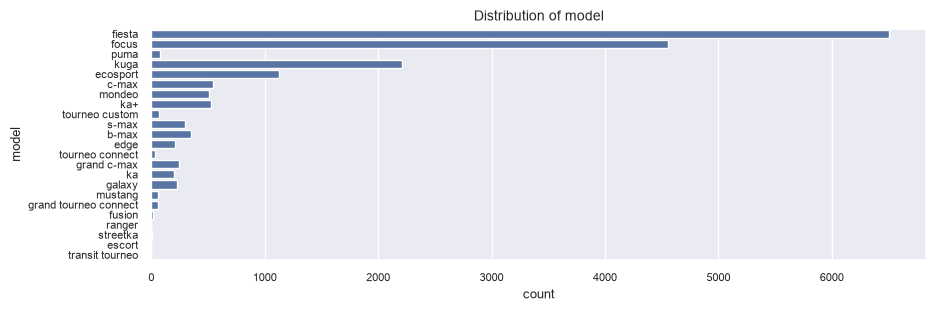

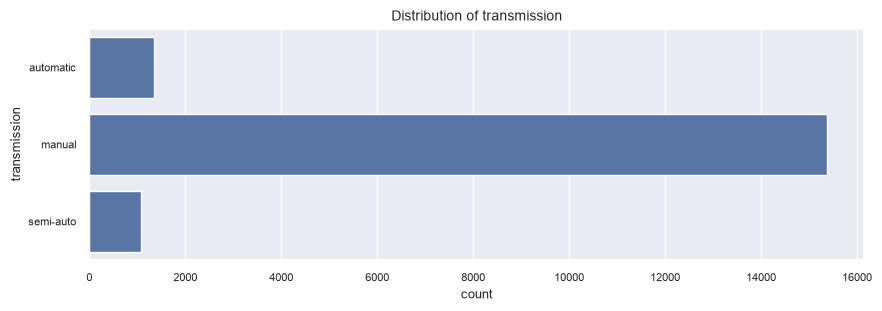

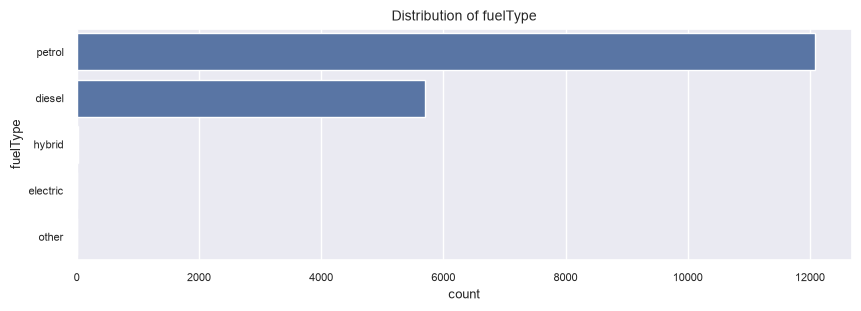

In [15]:
for col in categorical_cols:
    plt.figure(figsize=(10,3))
    sns.countplot(y=col, data=df)
    plt.title(f"Distribution of {col}")
    plt.show()

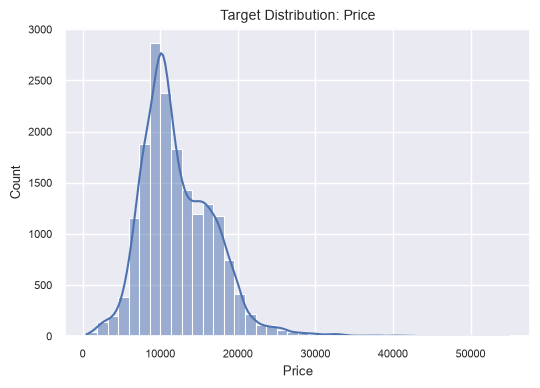

In [16]:
plt.figure(figsize=(6,4))
sns.histplot(df[TARGET_COL], bins=40, kde=True) # type: ignore
plt.title("Target Distribution: Price")
plt.xlabel("Price")
plt.show()

In [17]:
df[TARGET_COL].value_counts()

price
10000    164
11000    153
10500    146
12000    124
9000     117
        ... 
25050      1
13849      1
12849      1
16249      1
18122      1
Name: count, Length: 3511, dtype: int64

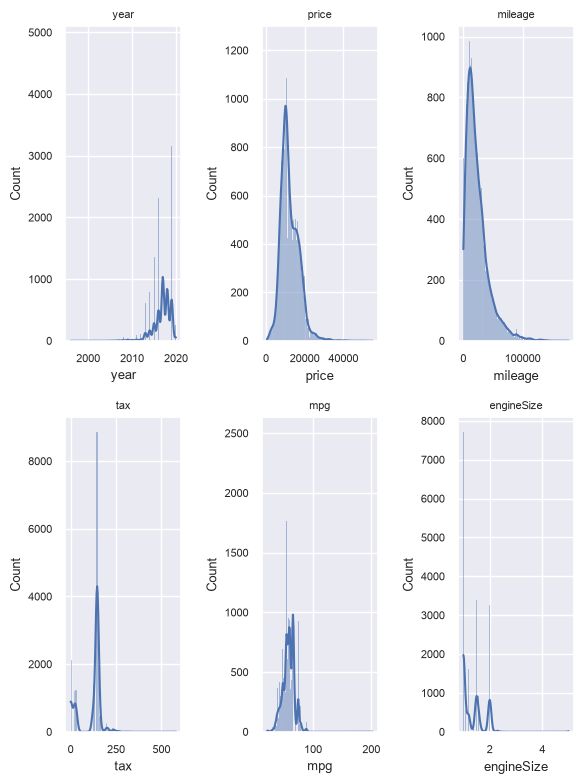

In [18]:
# histogram plot - distribution
fig, axes = plt.subplots(2,3,figsize=(6,8))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde=True, ax=axes[i]) # type: ignore
    axes[i].set_title(col, fontsize=8)
    
plt.tight_layout()
plt.show()

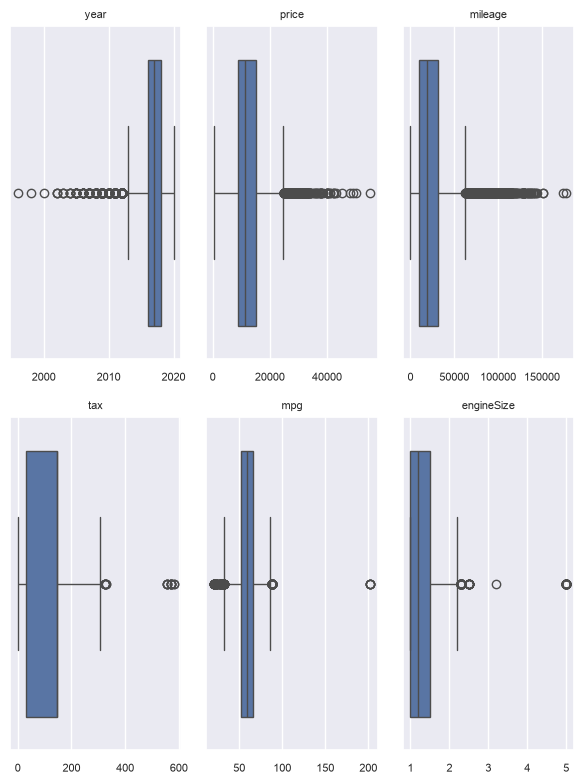

In [19]:
# outliers analysis - boxplot
fig, axes = plt.subplots(2,3,figsize=(6,8))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(x = df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("")
    
plt.tight_layout()
plt.show()

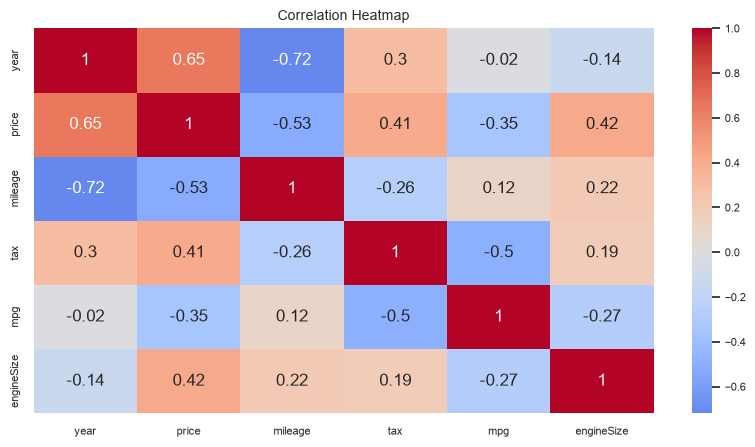

In [20]:
# Identify presence of highly correlated columns & feature relationships
plt.figure(figsize=(10,5))
sns.heatmap(
    df[numerical_cols].corr(),
    annot=True,
    cmap = 'coolwarm',
    center=0
)

plt.title(
'Correlation Heatmap'
)
plt.show()

In [21]:
# Correlation with Target
corr_with_target = df[numerical_cols].corr()[TARGET_COL].sort_values(ascending=False)
corr_with_target

price         1.000
year          0.645
engineSize    0.417
tax           0.406
mpg          -0.346
mileage      -0.530
Name: price, dtype: float64

Data Preprocessing

In [22]:
# Separate features and target.
x = df.drop(columns=[TARGET_COL]).copy()
y = df[TARGET_COL].copy()

if not y.gt(0).all():
    raise ValueError("Training target prices must all be greater than zero.")

print("Feature matrix:", x.shape)
print("Target rows:", len(y))


Feature matrix: (17811, 8)
Target rows: 17811


In [23]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print("Training rows:", len(x_train))
print("Test rows:", len(x_test))


Training rows: 14248
Test rows: 3563


Preprocessing Pipeline

In [24]:
numerical_features = x_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = x_train.select_dtypes(exclude=[np.number]).columns.tolist()

In [25]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)


In [26]:
preprocess = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

BaseLine Model (No CV, No Tuning)

In [27]:
baseline_pipe = Pipeline(
    steps=[
        ('preprocess', preprocess),
        ('model', LinearRegression())
    ]
)

In [28]:
# Preprocess the data and train the baseline model
baseline_pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['model','year','transmission',...,'tax','mpg','engineSize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

Evaluation of Baseline model

In [29]:
train_baseline_pred = baseline_pipe.predict(x_train)
test_baseline_pred = baseline_pipe.predict(x_test)

In [30]:
train_baseline_rmse = root_mean_squared_error(y_train, train_baseline_pred)
train_baseline_mae = mean_absolute_error(y_train, train_baseline_pred)
train_baseline_r2 = r2_score(y_train, train_baseline_pred)

print(f"RMSE: {train_baseline_rmse:.3f} \nMAE: {train_baseline_mae:.3f} \nR2: {train_baseline_r2:.3f}")

RMSE: 1840.224 
MAE: 1355.054 
R2: 0.848


In [31]:
test_baseline_rmse = root_mean_squared_error(y_test, test_baseline_pred)
test_baseline_mae = mean_absolute_error(y_test, test_baseline_pred)
test_baseline_r2 = r2_score(y_test, test_baseline_pred)

print(f"RMSE: {test_baseline_rmse:.3f} \nMAE: {test_baseline_mae:.3f} \nR2: {test_baseline_r2:.3f}")

RMSE: 1796.576 
MAE: 1342.647 
R2: 0.860


Model Selection & Optimization

In [32]:
# Models compared using the same training-only cross-validation folds.
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(random_state=RANDOM_STATE),
    "Lasso": Lasso(random_state=RANDOM_STATE, max_iter=10000),
    "RandomForestRegressor": RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "HistGradientBoostingRegressor": HistGradientBoostingRegressor(
        random_state=RANDOM_STATE,
    ),
}


In [33]:
k = 5
cv = KFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

In [34]:
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

In [35]:
rows = []

for name, model in models.items():
    pipe = Pipeline(
        steps=[
            ("preprocess", preprocess),
            ("model", model),
        ]
    )
    scores = cross_validate(
        pipe,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise",
    )
    rows.append({
        "model": name,
        "cv_rmse": -scores["test_rmse"].mean(),
        "cv_mae": -scores["test_mae"].mean(),
        "cv_r2": scores["test_r2"].mean(),
    })

cv_results = pd.DataFrame(rows).sort_values("cv_rmse").reset_index(drop=True)
display(cv_results)


,model,cv_rmse,cv_mae,cv_r2
0,HistGradientBoostingRegressor,1221.409,831.655,0.933
1,RandomForestRegressor,1292.693,884.582,0.925
2,Ridge,1851.050,1359.899,0.846
3,LinearRegression,1851.218,1360.137,0.846
4,Lasso,1851.950,1360.354,0.846


In [36]:
best_row = cv_results.iloc[0]
best_model_name = str(best_row["model"])
best_cv_rmse = float(best_row["cv_rmse"])

print("Cross-validation winner:", best_model_name)
print(f"Mean CV RMSE: {best_cv_rmse:,.3f}")


Cross-validation winner: HistGradientBoostingRegressor
Mean CV RMSE: 1,221.409


Hyperparameter Tuning

In [37]:
# Tune the model selected by cross-validation, rather than hardcoding HGB.
selected_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", models[best_model_name]),
    ]
)

search_spaces = {
    "LinearRegression": {
        "model__fit_intercept": [True, False],
    },
    "Ridge": {
        "model__alpha": [0.1, 1.0, 10.0, 100.0],
    },
    "Lasso": {
        "model__alpha": [0.001, 0.01, 0.1, 1.0],
    },
    "RandomForestRegressor": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": [1.0, "sqrt"],
    },
    "HistGradientBoostingRegressor": {
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [None, 3, 6],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0.0, 0.1, 1.0],
    },
}

param_distributions = search_spaces[best_model_name]
num_combinations = len(list(ParameterGrid(param_distributions)))
n_iter = min(25, num_combinations)

search = RandomizedSearchCV(
    estimator=selected_pipeline,
    param_distributions=param_distributions,
    n_iter=n_iter,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    verbose=1,
    error_score="raise",
)


In [38]:
print(f"Searching {n_iter} of {num_combinations} parameter combinations.")


Searching 25 of 243 parameter combinations.


In [39]:
search.fit(x_train, y_train)
final_model = search.best_estimator_

print("Selected model:", best_model_name)
print("Best parameters:", search.best_params_)
print(f"Best CV RMSE: {-search.best_score_:,.3f}")


Fitting 5 folds for each of 25 candidates, totalling 125 fits
Selected model: HistGradientBoostingRegressor
Best parameters: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_depth': None, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.0}
Best CV RMSE: 1,231.453


In [40]:
# Best estimator is refitted on the complete training split by RandomizedSearchCV.
# Keep this explicit alias for readability in the remaining notebook cells.
best_model = final_model


In [41]:
search.best_params_


{'model__min_samples_leaf': 20,
 'model__max_leaf_nodes': 63,
 'model__max_depth': None,
 'model__learning_rate': 0.05,
 'model__l2_regularization': 0.0}

### Evaluate the selected, tuned model
The remaining evaluation cells now use `final_model`, which is the estimator selected and refitted by the model-specific randomized search.

In [42]:
# Best estimator is already fitted by RandomizedSearchCV(refit=True).
final_model = search.best_estimator_


In [43]:
print("Model chosen for final evaluation:", best_model_name)
print("Final estimator type:", type(final_model.named_steps["model"]).__name__)


Model chosen for final evaluation: HistGradientBoostingRegressor
Final estimator type: HistGradientBoostingRegressor


In [54]:
train_final_pred = final_model.predict(x_train)

train_final_rmse = root_mean_squared_error(y_train, train_final_pred)
train_final_mae = mean_absolute_error(y_train, train_final_pred)
train_final_r2 = r2_score(y_train, train_final_pred)

print(
    f"Train RMSE: {train_final_rmse:,.3f}\n"
    f"Train MAE: {train_final_mae:,.3f}\n"
    f"Train R2: {train_final_r2:.6f}"
)


Train RMSE: 1,094.539
Train MAE: 770.214
Train R2: 0.946253


In [55]:
test_final_pred = final_model.predict(x_test)

test_final_rmse = root_mean_squared_error(y_test, test_final_pred)
test_final_mae = mean_absolute_error(y_test, test_final_pred)
test_final_r2 = r2_score(y_test, test_final_pred)

print(
    f"Test RMSE: {test_final_rmse:,.3f}\n"
    f"Test MAE: {test_final_mae:,.3f}\n"
    f"Test R2: {test_final_r2:.6f}"
)


Test RMSE: 1,158.023
Test MAE: 828.295
Test R2: 0.941664


In [46]:
FEATURE_COLUMNS = [
    "model",
    "year",
    "transmission",
    "mileage",
    "fuelType",
    "tax",
    "mpg",
    "engineSize",
]


def predict_ford_price(
    ai_model,
    model: str,
    year: int,
    transmission: str,
    mileage: int,
    fuelType: str,
    tax: int,
    mpg: float,
    engineSize: float,
) -> float:
    """Predict a price for one Ford car using the trained pipeline."""
    new_row = pd.DataFrame(
        [{
            "model": str(model).strip().casefold(),
            "year": year,
            "transmission": str(transmission).strip().casefold(),
            "mileage": mileage,
            "fuelType": str(fuelType).strip().casefold(),
            "tax": tax,
            "mpg": mpg,
            "engineSize": engineSize,
        }],
        columns=FEATURE_COLUMNS,
    )

    prediction = float(ai_model.predict(new_row)[0])
    if not np.isfinite(prediction) or prediction < 0:
        raise ValueError("The model returned an invalid price prediction.")
    return prediction


example_pred = predict_ford_price(
    ai_model=final_model,
    model="Fiesta",
    year=2012,
    transmission="Automatic",
    mileage=10000,
    fuelType="Diesel",
    tax=125,
    mpg=57.7,
    engineSize=1.5,
)


In [47]:
example_pred


7890.356658717457

In [48]:
# Test-set predictions and absolute/percentage errors.
test_predictions = final_model.predict(x_test)

results_with_cars = x_test.copy()
results_with_cars["Actual Price"] = y_test.to_numpy()
results_with_cars["Predicted Price"] = test_predictions
results_with_cars["Error"] = (
    results_with_cars["Actual Price"] - results_with_cars["Predicted Price"]
)
results_with_cars["Absolute Error"] = results_with_cars["Error"].abs()
results_with_cars["Absolute Percentage Error"] = (
    results_with_cars["Absolute Error"] / results_with_cars["Actual Price"] * 100
)

display(results_with_cars.head(10))


,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,Actual Price,Predicted Price,Error,Absolute Error,Absolute Percentage Error
1026,galaxy,2017,manual,50565,diesel,150,56.500,2.000,14995,15307.327,-312.327,312.327,2.083
16825,focus,2005,manual,87530,petrol,235,39.800,2.000,2295,3103.413,-808.413,808.413,35.225
2848,focus,2016,manual,13820,petrol,200,41.500,2.000,14950,16905.810,-1955.810,1955.810,13.082
11444,focus,2017,manual,26181,petrol,145,41.500,2.000,17890,16870.832,1019.168,1019.168,5.697
9994,focus,2018,manual,26500,petrol,150,60.100,1.000,11795,11933.900,-138.900,138.900,1.178
10927,fiesta,2015,manual,33000,petrol,0,65.700,1.000,8263,7753.464,509.536,509.536,6.166
15294,fiesta,2016,manual,32737,petrol,0,65.700,1.000,8000,8214.498,-214.498,214.498,2.681
2301,kuga,2019,manual,10465,diesel,145,37.700,2.000,20500,21316.614,-816.614,816.614,3.983
17739,c-max,2016,automatic,26077,diesel,20,64.200,1.500,10999,10106.772,892.228,892.228,8.112
13810,ecosport,2018,manual,16299,petrol,145,54.300,1.000,15000,13311.812,1688.188,1688.188,11.255


In [49]:
# Worst predictions by absolute price error.
worst_predictions = results_with_cars.sort_values(
    by="Absolute Error",
    ascending=False,
)
display(worst_predictions.head(10))


,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,Actual Price,Predicted Price,Error,Absolute Error,Absolute Percentage Error
2002,focus,2018,manual,13847,petrol,145,58.900,1.000,25998,13544.584,12453.416,12453.416,47.901
10836,focus,2020,automatic,10,petrol,145,39.800,1.500,30999,23082.808,7916.192,7916.192,25.537
16753,mondeo,2008,manual,1,diesel,200,47.900,2.000,1299,8888.560,-7589.560,7589.560,584.262
13148,focus,2019,automatic,6000,petrol,145,51.400,1.000,23990,17079.891,6910.109,6910.109,28.804
16179,focus,2018,manual,19000,petrol,145,67.300,NaN,18389,11551.899,6837.101,6837.101,37.180
17083,kuga,2018,automatic,21516,diesel,140,54.300,2.000,24995,18293.244,6701.756,6701.756,26.812
505,tourneo custom,2019,manual,5100,diesel,145,31.700,2.000,20990,26854.300,-5864.300,5864.300,27.939
7660,focus,2017,manual,10057,petrol,235,36.700,2.300,32000,26384.069,5615.931,5615.931,17.550
2455,focus,2019,automatic,3541,diesel,145,74.300,1.500,23695,18236.974,5458.026,5458.026,23.035
7634,s-max,2017,semi-auto,16815,diesel,145,54.300,2.000,24000,18832.271,5167.729,5167.729,21.532


In [50]:
# Best predictions by absolute price error.
best_predictions = results_with_cars.sort_values(
    by="Absolute Error",
    ascending=True,
)
display(best_predictions.head(10))


,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,Actual Price,Predicted Price,Error,Absolute Error,Absolute Percentage Error
16182,ka+,2019,manual,10000,petrol,145,47.900,NaN,9999,9998.714,0.286,0.286,0.003
13743,focus,2012,manual,59000,petrol,145,47.900,1.600,5995,5995.716,-0.716,0.716,0.012
1527,ecosport,2019,manual,1091,petrol,145,51.400,1.000,16998,16997.214,0.786,0.786,0.005
14379,mondeo,2016,manual,128000,diesel,0,78.500,1.500,7492,7492.916,-0.916,0.916,0.012
14449,grand c-max,2016,manual,32151,diesel,30,64.200,1.500,9834,9832.956,1.044,1.044,0.011
6021,fiesta,2018,manual,39478,petrol,150,56.500,1.000,10360,10357.889,2.111,2.111,0.020
4031,fiesta,2018,semi-auto,4213,petrol,145,54.300,1.000,13500,13502.234,-2.234,2.234,0.017
7273,kuga,2017,manual,25220,diesel,30,64.200,1.500,13200,13202.504,-2.504,2.504,0.019
167,focus,2015,manual,25878,diesel,20,67.300,2.000,12998,13000.703,-2.703,2.703,0.021
12780,fiesta,2019,manual,7289,petrol,145,60.100,1.000,14999,15002.104,-3.104,3.104,0.021


In [51]:
# MAPE is calculated with the sklearn metric; the target was validated as positive.
mape = mean_absolute_percentage_error(y_test, test_predictions) * 100
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")


Mean Absolute Percentage Error (MAPE): 7.16%


In [52]:
# Save the complete fitted pipeline (preprocessing + estimator).
# Set FORD_MODEL_PATH to an absolute path also used by the API process.
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, MODEL_PATH)
print("Model saved to:", MODEL_PATH)

# Confirm the saved artifact reloads and produces the same sample predictions.
reloaded_model = joblib.load(MODEL_PATH)
np.testing.assert_allclose(
    final_model.predict(x_test.iloc[:5]),
    reloaded_model.predict(x_test.iloc[:5]),
)
print("Saved artifact reload test passed.")


Model saved to: E:\AI\Projects\Project02_FordCardPricePrediction\models\ford_price_model.pkl
Saved artifact reload test passed.


In [53]:
print("Training and evaluation complete.")
print("Final model:", best_model_name)
print("Artifact:", MODEL_PATH)
print("Test RMSE:", round(float(test_final_rmse), 3))
print("Test MAE:", round(float(test_final_mae), 3))
print("Test R2:", round(float(test_final_r2), 6))
print("Test MAPE (%):", round(float(mape), 3))


Training and evaluation complete.
Final model: HistGradientBoostingRegressor
Artifact: E:\AI\Projects\Project02_FordCardPricePrediction\models\ford_price_model.pkl
Test RMSE: 1158.023
Test MAE: 828.295
Test R2: 0.941664
Test MAPE (%): 7.161
